# People, in Balance
## A People Data & Operations portfolio analysis

Independent, AI-assisted project by Margarita Bermejo Cano. No affiliation with Waystone.

**Data sources:** official CSO workforce aggregates and a synthetic multi-system HR dataset. Operational results describe the demonstration dataset.

## EDA decision log

- **Source:** CSO EHQ03, official API; snapshot SHA-256 `02cea5148d39cd8dadd1fa91687d1b2751d2da50af224d67e58f4314108f057b`.
- **Scale:** 130,536 published cube cells; 3,150 selected cells; full data, no sampling.
- **Selection:** all employees, five unadjusted metrics, all published sectors, 2019Q1 onward. Overlapping sector aggregates are analysed separately.
- **Level:** in-depth operational analysis: quality, reconciliation, exceptions, distributions, relationships, controls and limitations.
- **Synthetic source:** seed 731; 360 fictional employees; as-of 2026-10-31; seven independent-format feeds. No real sensitive records.
- **Analytical approach:** deterministic validation and reconciliation controls address the operational reporting requirements. Predictive employee scoring and causal inference are outside scope.
- **Uncertainty:** public revisions and missing inferential variances; fictional payroll assumptions; statutory working-time periods; holiday calendars; real HR/legal judgement.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
from analysis import run
from build import public_findings, plots
public, provenance, sources, result = run()
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 20)
OUTPUT = ROOT / 'outputs'
display(pd.DataFrame([{'source': name, 'rows': len(frame), 'columns': len(frame.columns),'memory_MB': round(frame.memory_usage(deep=True).sum()/1024**2,2)} for name,frame in sources.items()]))

{
  "seed": 731,
  "as_of": "2026-10-31",
  "fixture_people": 360,
  "hr_raw_rows": 364,
  "hr_unique_keys": 360,
  "hr_exact_duplicates_removed": 3,
  "hr_conflicting_keys": 1,
  "hr_critical_records_excluded": 4,
  "hr_valid_records": 355,
  "active_headcount": 344,
  "active_fte": 324.0,
  "payroll_raw_rows": 353,
  "payroll_exact_duplicates_removed": 2,
  "payroll_conflicting_keys": 1,
  "payroll_resolved_rows": 348,
  "reconciled_employees": 337,
  "payroll_amount_exceptions": 3,
  "comparable_payroll_rows": 340,
  "expected_comparable_eur": 1788429.38,
  "actual_comparable_eur": 1790276.71,
  "signed_payroll_delta_eur": 1847.33,
  "absolute_payroll_delta_eur": 2652.67,
  "absence_raw_rows": 87,
  "absence_exact_duplicates_removed": 4,
  "absence_valid_episodes": 80,
  "absence_naive_valid_days": 297,
  "absence_unique_days": 296,
  "absence_overlap_days_removed": 1,
  "absence_rate_pct": 0.975,
  "working_time_daily_rows": 29745,
  "time_above_screen": 7,
  "time_incomplete": 1,


,source,rows,columns,memory_MB
0,hr_raw,364,8,0.16
1,payroll_raw,353,8,0.13
2,approvals,23,6,0.01
3,absence_raw,87,6,0.03
4,time_raw,29745,7,10.37
5,visa_raw,26,8,0.01
6,cases_raw,30,8,0.02
7,fixture_roster,360,7,0.12


## 1 / Data structure and completeness
Review the units, reporting grains and missing values in each source. Missing critical employment or payroll values remain unknown and are referred for resolution.

In [2]:
display(public.head(5)); display(public.tail(5)); display(public.dtypes.to_frame('dtype'))
display(public.describe(include='all'))
display(pd.DataFrame({'missing': public.isna().sum(), 'missing_pct': public.isna().mean()*100}))
display(sources['hr_raw'].head(5))
display(pd.DataFrame({name: frame.replace('', np.nan).isna().sum() for name, frame in sources.items()}).fillna('not a field'))
print('Selected public key duplicates:', public.duplicated(['metric_code','sector_code','quarter']).sum())
print('Exact raw HR payload duplicates:', sources['hr_raw'].drop(columns='source_row').duplicated().sum())

,metric_code,metric,quarter,sector_code,sector,value,unit
3696,EHQ03C01,Employment,2019Q1,-,All NACE economic sectors,1895000.0,Number
3780,EHQ03C01,Employment,2019Q2,-,All NACE economic sectors,1897300.0,Number
3864,EHQ03C01,Employment,2019Q3,-,All NACE economic sectors,1928600.0,Number
3948,EHQ03C01,Employment,2019Q4,-,All NACE economic sectors,1947200.0,Number
4032,EHQ03C01,Employment,2020Q1,-,All NACE economic sectors,1941100.0,Number


,metric_code,metric,quarter,sector_code,sector,value,unit
49388,EHQ03C08,Average Hourly Total Labour Costs,2025Q2,Y7400,"Arts, entertainment, recreation and other serv...",27.02,Euro
49472,EHQ03C08,Average Hourly Total Labour Costs,2025Q3,Y7400,"Arts, entertainment, recreation and other serv...",26.74,Euro
49556,EHQ03C08,Average Hourly Total Labour Costs,2025Q4,Y7400,"Arts, entertainment, recreation and other serv...",27.84,Euro
49640,EHQ03C08,Average Hourly Total Labour Costs,2026Q1,Y7400,"Arts, entertainment, recreation and other serv...",28.95,Euro
49724,EHQ03C08,Average Hourly Total Labour Costs,2026Q2,Y7400,"Arts, entertainment, recreation and other serv...",28.57,Euro


,dtype
metric_code,object
metric,object
quarter,object
sector_code,object
sector,object
value,float64
unit,object


,metric_code,metric,quarter,sector_code,sector,value,unit
count,3150,3150,3150,3150,3150,3.150000e+03,3150
unique,5,5,30,21,21,NaN,3
top,EHQ03C01,Employment,2019Q1,-,All NACE economic sectors,NaN,Euro
freq,630,630,105,150,150,NaN,1890
mean,NaN,NaN,NaN,NaN,NaN,4.467940e+04,NaN
std,NaN,NaN,NaN,NaN,NaN,2.142700e+05,NaN
min,NaN,NaN,NaN,NaN,NaN,7.390000e+00,NaN
25%,NaN,NaN,NaN,NaN,NaN,2.902500e+01,NaN
50%,NaN,NaN,NaN,NaN,NaN,3.790000e+01,NaN
75%,NaN,NaN,NaN,NaN,NaN,1.121240e+03,NaN


,missing,missing_pct
metric_code,0,0.0
metric,0,0.0
quarter,0,0.0
sector_code,0,0.0
sector,0,0.0
value,0,0.0
unit,0,0.0


,source_row,employee_id,department,annual_salary_eur,fte,start_date,end_date,contract
0,HR-0001,emp0001,ops,75700.0,1.0,2021-01-01,,Permanent
1,HR-0002,EMP0002,Client Services,61100.0,1.0,2022-01-01,,Permanent
2,HR-0003,EMP0003,Risk & Compliance,62300.0,1.0,2023-01-01,,Permanent
3,HR-0004,EMP0004,Technology,75900.0,0.6,2024-01-01,,Permanent
4,HR-0005,EMP0005,Corporate,97900.0,1.0,2020-01-01,,Permanent


C:\Users\mbermejocano\AppData\Local\Temp\ipykernel_40260\3677643262.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(pd.DataFrame({name: frame.replace('', np.nan).isna().sum() for name, frame in sources.items()}).fillna('not a field'))


,hr_raw,payroll_raw,approvals,absence_raw,time_raw,visa_raw,cases_raw,fixture_roster
allowance_eur,not a field,0.0,not a field,not a field,not a field,not a field,not a field,not a field
amount_eur,not a field,not a field,0.0,not a field,not a field,not a field,not a field,not a field
annual_salary_eur,1.0,not a field,not a field,not a field,not a field,not a field,not a field,0.0
approval_id,not a field,not a field,0.0,not a field,not a field,not a field,not a field,not a field
base_eur,not a field,0.0,not a field,not a field,not a field,not a field,not a field,not a field
break_minutes,not a field,not a field,not a field,not a field,0.0,not a field,not a field,not a field
case_id,not a field,not a field,not a field,not a field,not a field,0.0,0.0,not a field
case_type,not a field,not a field,not a field,not a field,not a field,not a field,0.0,not a field
contract,0.0,not a field,not a field,not a field,not a field,not a field,not a field,0.0
date,not a field,not a field,not a field,not a field,0.0,not a field,not a field,not a field


Selected public key duplicates: 0
Exact raw HR payload duplicates: 3


## 2 / Public workforce context
CSO means describe enterprise-survey aggregates. Individual salary benchmarking requires a suitable employee-level comparison. Employment, earnings and paid hours use different concepts. Nominal, unadjusted changes may reflect seasonality, bonuses or workforce composition. Year-on-year comparisons provide context; inflation adjustment is outside scope.

,metric_code,sector_code,quarter,latest,baseline,index,yoy_pct
0,EHQ03C01,-,2026Q2,2368400.00,1895000.00,124.982,1.893
8,EHQ03C01,K,2026Q2,116000.00,84900.00,136.631,7.209
21,EHQ03C02,-,2026Q2,1046.88,771.43,135.706,3.900
29,EHQ03C02,K,2026Q2,1556.66,1339.56,116.207,3.023
42,EHQ03C03,-,2026Q2,31.96,24.05,132.890,3.800
50,EHQ03C03,K,2026Q2,43.27,37.86,114.289,4.745
63,EHQ03C05,-,2026Q2,32.80,32.10,102.181,0.306
71,EHQ03C05,K,2026Q2,36.00,35.40,101.695,-1.639
84,EHQ03C08,-,2026Q2,37.73,27.74,136.013,4.054
92,EHQ03C08,K,2026Q2,55.56,46.67,119.049,5.849


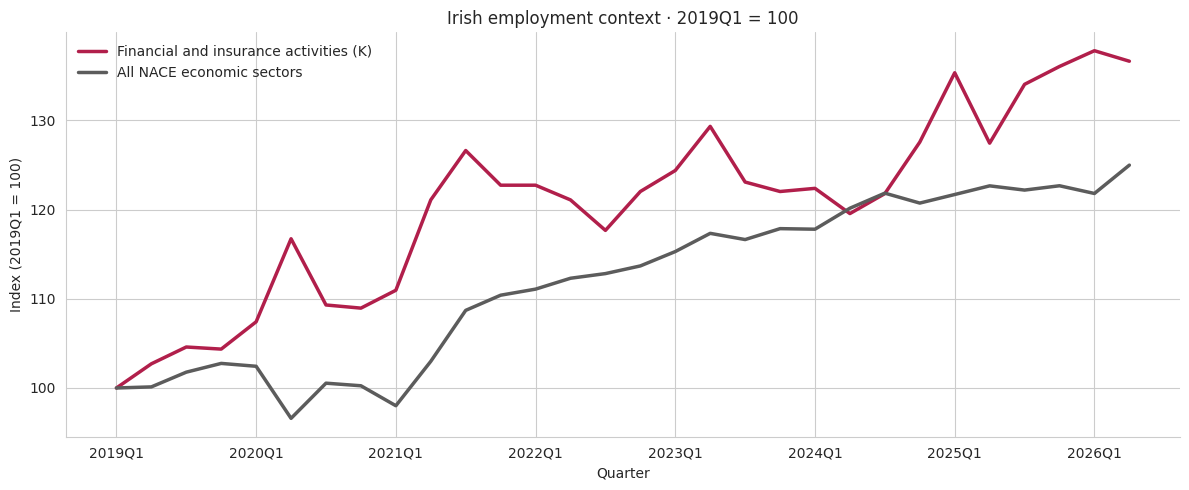

In [3]:
findings = public_findings(public)
findings.to_csv(OUTPUT / 'tables' / 'public_findings.csv', index=False)
display(findings[findings['sector_code'].isin(['K','-'])])
plots(public, result)
display(Image(filename=str(OUTPUT / 'plots' / 'public_employment.png')))

## 3 / Relationships and outlier sensitivity
Within finance/insurance, inspect changes rather than correlations between trending levels. These are only 29 quarterly differences, serially dependent and based on aggregate survey estimates. Pearson correlations and IQR outliers are used as descriptive diagnostics. Serial dependence, sample size and aggregate survey estimation limit statistical inference; formal significance and causal tests are outside scope.

metric,Average Hourly Earnings,Average Hourly Total Labour Costs,Average Weekly Earnings,Average Weekly Paid Hours,Employment
count,29.000000,29.000000,29.000000,29.000000,29.000000
mean,1.116153,1.153033,1.168825,0.061628,1.152767
std,11.839942,10.827522,11.817733,0.870715,3.847364
min,-15.831296,-14.385908,-15.009063,-1.416431,-6.357215
25%,-9.774436,-7.542318,-9.084378,-0.568182,-0.861244
50%,-3.029476,-3.368101,-3.306700,0.000000,1.493849
75%,5.882353,9.437428,6.240076,0.849858,3.703704
max,22.898904,21.077867,24.781456,1.690141,9.129512


metric,Average Hourly Earnings,Average Hourly Total Labour Costs,Average Weekly Earnings,Average Weekly Paid Hours,Employment
skew,0.424359,0.359076,0.473611,0.141433,0.037428
kurt,-1.049320,-1.182388,-0.973835,-1.128229,-0.089256


,IQR diagnostic quarters
metric,
Average Hourly Earnings,0
Average Hourly Total Labour Costs,0
Average Weekly Earnings,0
Average Weekly Paid Hours,0
Employment,0


metric,Average Hourly Earnings,Average Hourly Total Labour Costs,Average Weekly Earnings,Average Weekly Paid Hours,Employment
metric,,,,,
Average Hourly Earnings,1.000000,0.985690,0.997411,-0.078313,0.102265
Average Hourly Total Labour Costs,0.985690,1.000000,0.985656,-0.046748,0.091943
Average Weekly Earnings,0.997411,0.985656,1.000000,-0.007367,0.114764
Average Weekly Paid Hours,-0.078313,-0.046748,-0.007367,1.000000,0.173375
Employment,0.102265,0.091943,0.114764,0.173375,1.000000


metric,Average Hourly Earnings,Average Hourly Total Labour Costs,Average Weekly Earnings,Average Weekly Paid Hours,Employment
metric,,,,,
Average Hourly Earnings,1.000000,0.989069,0.997520,-0.046270,0.151876
Average Hourly Total Labour Costs,0.989069,1.000000,0.987249,-0.036777,0.137430
Average Weekly Earnings,0.997520,0.987249,1.000000,0.023277,0.159196
Average Weekly Paid Hours,-0.046270,-0.036777,0.023277,1.000000,0.077026
Employment,0.151876,0.137430,0.159196,0.077026,1.000000


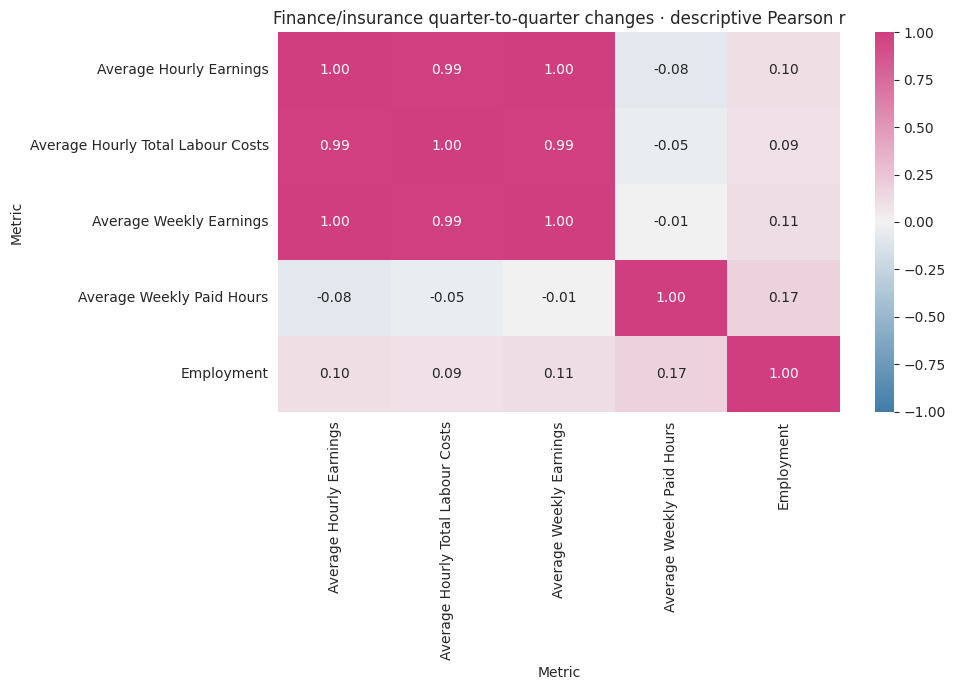

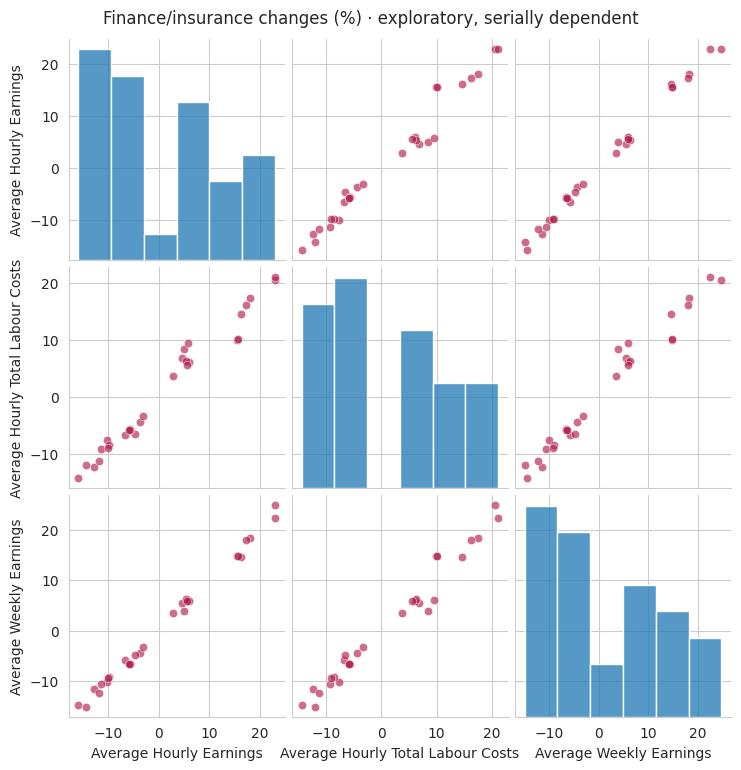

In [4]:
wide = public[public['sector_code'].eq('K')].pivot(index='quarter', columns='metric', values='value')
changes = wide.pct_change().dropna()*100
display(changes.describe())
display(changes.agg(['skew','kurt']))
q1, q3 = changes.quantile(.25), changes.quantile(.75)
flag = changes.lt(q1-1.5*(q3-q1)) | changes.gt(q3+1.5*(q3-q1))
display(flag.sum().to_frame('IQR diagnostic quarters'))
display(changes.corr())
display(changes.loc[~changes.index.str.startswith('2020')].corr())
display(Image(filename=str(OUTPUT / 'plots' / 'public_change_correlations.png')))
display(Image(filename=str(OUTPUT / 'plots' / 'public_change_pairs.png')))

## 4 / Data validation and reporting population
Normalise keys and field types, collapse only equivalent payloads, quarantine conflicts and reject critical-field failures. The synthetic roster contains 360 employee keys. Validation and employment-date rules define the active reporting population. Exact repeats and conflicting records have different treatment.

In [5]:
display(pd.Series(result['qa']).to_frame('value'))
display(result['exceptions'][result['exceptions']['area'].eq('HR master')])
display(result['active_hr'].groupby('department').agg(headcount=('employee_id','size'),fte=('fte','sum')))

,value
seed,731
as_of,2026-10-31
fixture_people,360
hr_raw_rows,364
hr_unique_keys,360
hr_exact_duplicates_removed,3
hr_conflicting_keys,1
hr_critical_records_excluded,4
hr_valid_records,355
active_headcount,344


,exception_id,area,employee_id,code,severity,detail,evidence,action,owner,status,amount_eur
0,EX-001,HR master,EMP0060,Conflicting master,Review,Two different salary records share one employe...,"HR-0060, HR-0364",Quarantine both; ask People Systems to confirm...,People Systems,Open / demonstration,NaN
1,EX-002,HR master,EMP0007,Critical field,Review,Unusable salary.,HR-0007,Obtain a verified source correction for the cr...,People Systems,Open / demonstration,NaN
2,EX-003,HR master,EMP0020,Critical field,Review,Unusable department.,HR-0020,Obtain a verified source correction for the cr...,People Systems,Open / demonstration,NaN
3,EX-004,HR master,EMP0030,Critical field,Review,Unusable hire date.,HR-0030,Obtain a verified source correction for the cr...,People Systems,Open / demonstration,NaN
4,EX-005,HR master,EMP0041,Critical field,Review,Unusable FTE.,HR-0041,Obtain a verified source correction for the cr...,People Systems,Open / demonstration,NaN


,headcount,fte
department,,
Client Services,69,64.6
Corporate,67,63.6
Operations,69,66.4
Risk & Compliance,69,64.0
Technology,70,65.4


## 5 / Payroll reconciliation and investigation
Approved full-time annual salary / 12 x FTE + approved recurring allowance + approved variable pay. No mid-month proration, tax, PRSI, pension or net-pay checks. Unmatched or unknown amounts are excluded from the common comparable sum. Report signed and absolute discrepancies to show both the net effect and the total variance magnitude. Root-cause examples are deliberately introduced in the synthetic data.

,employees
result,
Reconciled,337
Amount exception,3
Missing / quarantined payment,3
Unknown gross,1


,employee_id,expected_gross_eur,gross_eur,delta_eur,result
4,EMP0005,8278.33,10278.33,2000.00,Amount exception
9,EMP0011,3113.33,3363.33,250.00,Amount exception
16,EMP0018,5556.00,5153.33,-402.67,Amount exception
21,EMP0024,2733.33,NaN,NaN,Unknown gross
28,EMP0033,5340.00,NaN,NaN,Missing / quarantined payment
92,EMP0099,6625.00,NaN,NaN,Missing / quarantined payment
94,EMP0101,7233.33,NaN,NaN,Missing / quarantined payment


,approval_id,employee_id,kind,effective_date,amount_eur,status
0,APR-018,EMP0018,Salary,2026-10-01,65232.0,Approved
1,APR-044,EMP0044,Salary,2026-10-01,59940.0,Approved
2,APR-055,EMP0055,Variable,2026-10-01,420.0,Approved
20,ALW-018,EMP0018,Allowance,2026-10-01,120.0,Approved


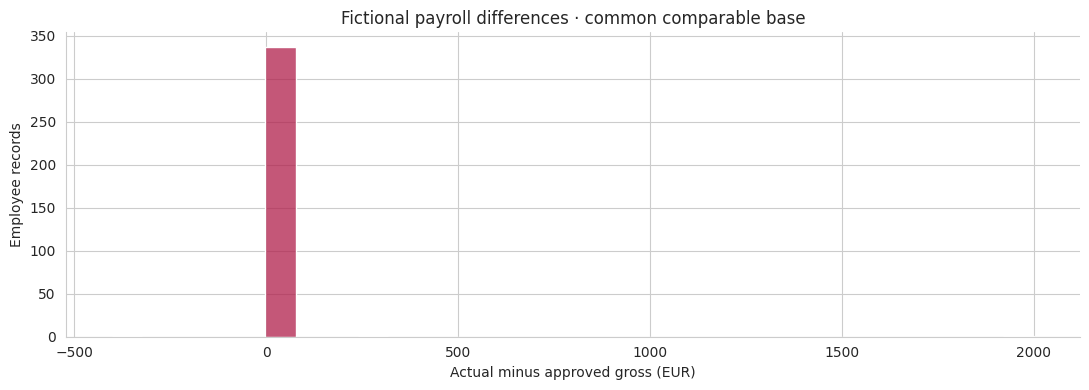

In [6]:
recon = result['reconciliation']
display(recon['result'].value_counts().to_frame('employees'))
display(recon[recon['result'].ne('Reconciled')][['employee_id','expected_gross_eur','gross_eur','delta_eur','result']])
display(sources['approvals'][sources['approvals']['employee_id'].isin(['EMP0018','EMP0044','EMP0055'])])
common = recon[recon['delta_eur'].notna()]
assert round(common['gross_eur'].sum()-common['expected_gross_eur'].sum(),2) == result['qa']['signed_payroll_delta_eur']
assert recon.loc[recon['employee_id'].isin(['EMP0044','EMP0055']),'result'].eq('Reconciled').all()
display(Image(filename=str(OUTPUT / 'plots' / 'payroll_distribution.png')))

## 6 / Absence rates and scheduled exposure
Deduplicate episodes, validate dates and keys, union scheduled lost dates and reconcile worked-time collisions. The denominator uses weekdays within employment dates multiplied by FTE x 7.5 hours/day. Public-holiday and custom-roster adjustments are outside scope. The analysis uses synthetic scheduling metadata and excludes health information.

,month,department,scheduled_hours,lost_hours,rate_pct
0,2026-07,Operations,11764.5,118.5,1.007
1,2026-07,Client Services,11419.5,67.5,0.591
2,2026-07,Risk & Compliance,11385.0,144.0,1.265
3,2026-07,Technology,11592.0,97.5,0.841
4,2026-07,Corporate,11316.0,130.5,1.153
5,2026-08,Operations,10741.5,105.0,0.978
6,2026-08,Client Services,10426.5,60.0,0.575
7,2026-08,Risk & Compliance,10395.0,118.5,1.140
8,2026-08,Technology,10584.0,262.5,2.480
9,2026-08,Corporate,10332.0,39.0,0.377


,exception_id,area,employee_id,code,severity,detail,evidence,action,owner,status,amount_eur
21,EX-022,Absence,EMP0020,Invalid episode,Review,Invalid date range or unresolved HR reference.,ABS-071,Correct the episode or reconcile its employee ...,People Operations,Open / demonstration,NaN
22,EX-023,Absence,EMP0050,Invalid episode,Review,Invalid date range or unresolved HR reference.,ABS-082,Correct the episode or reconcile its employee ...,People Operations,Open / demonstration,NaN
23,EX-024,Absence,EMP9999,Invalid episode,Review,Invalid date range or unresolved HR reference.,ABS-083,Correct the episode or reconcile its employee ...,People Operations,Open / demonstration,NaN
24,EX-025,Absence,EMP0115,Overlapping absence,Review,1 scheduled day(s) appear in more than one epi...,ABS-081,Review the overlapping episodes; count each sc...,People Operations,Open / demonstration,NaN
25,EX-026,Absence,EMP0115,Absence / time conflict,Review,A scheduled sickness day also has recorded wor...,"2026-09-21, 2026-09-22",Reconcile the absence episode and time record ...,People Operations,Open / demonstration,NaN


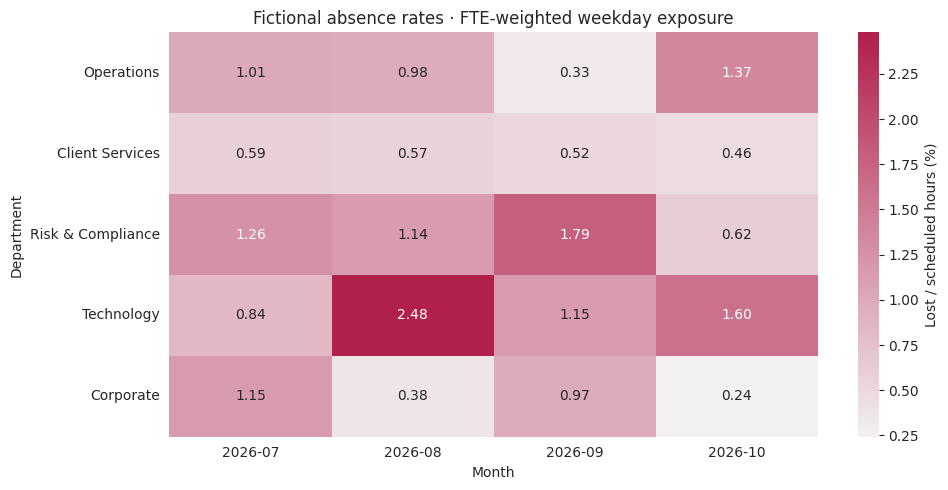

In [7]:
display(result['absence_summary'])
display(result['exceptions'][result['exceptions']['area'].eq('Absence')])
assert result['qa']['absence_naive_valid_days'] - result['qa']['absence_overlap_days_removed'] == result['qa']['absence_unique_days']
display(Image(filename=str(OUTPUT / 'plots' / 'absence_heatmap.png')))

## 7 / Working-time review and completeness
The WRC general rule is a 48-hour average over four calendar months, with exceptions. This lab uses 17 complete weeks (2026-07-06 to 2026-10-30) as an operational screen only. Coverage gaps remain unknown; annual/sick-leave adjustments, weekly rest, reference-period exceptions and compensatory rest need HR/legal review. Peak weeks and reference-period averages are reviewed separately. A statutory assessment would require the applicable period, adjustments and qualified legal interpretation.

,employees,mean_observed
result,,
Above 48h / review,7,54.352941
Below screen,336,34.968487
Incomplete / review,1,55.000000


,employee_id,department,weeks,average_hours,peak_hours,complete_weeks,result
93,EMP0100,Corporate,17,55.000000,55.0,17,Above 48h / review
96,EMP0103,Risk & Compliance,16,55.000000,55.0,16,Incomplete / review
143,EMP0150,Corporate,17,38.823529,60.0,17,Below screen
163,EMP0170,Corporate,17,36.529412,43.5,17,Below screen


,exception_id,area,employee_id,code,severity,detail,evidence,action,owner,status,amount_eur
26,EX-027,Working time,EMP0100,Above 48h / review,Review,17 complete weeks; observed mean 55.00 hours.,"Daily time records, 2026-07-06 to 2026-10-30","Review actual hours, the statutory reference p...",People Operations,Open / demonstration,NaN
27,EX-028,Working time,EMP0101,Above 48h / review,Review,17 complete weeks; observed mean 55.00 hours.,"Daily time records, 2026-07-06 to 2026-10-30","Review actual hours, the statutory reference p...",People Operations,Open / demonstration,NaN
28,EX-029,Working time,EMP0102,Above 48h / review,Review,17 complete weeks; observed mean 55.00 hours.,"Daily time records, 2026-07-06 to 2026-10-30","Review actual hours, the statutory reference p...",People Operations,Open / demonstration,NaN
29,EX-030,Working time,EMP0103,Incomplete / review,Review,16 complete weeks; observed mean 55.00 hours.,"Daily time records, 2026-07-06 to 2026-10-30","Review actual hours, the statutory reference p...",People Operations,Open / demonstration,NaN
30,EX-031,Working time,EMP0104,Above 48h / review,Review,17 complete weeks; observed mean 55.00 hours.,"Daily time records, 2026-07-06 to 2026-10-30","Review actual hours, the statutory reference p...",People Operations,Open / demonstration,NaN
31,EX-032,Working time,EMP0105,Above 48h / review,Review,17 complete weeks; observed mean 51.12 hours.,"Daily time records, 2026-07-06 to 2026-10-30","Review actual hours, the statutory reference p...",People Operations,Open / demonstration,NaN
32,EX-033,Working time,EMP0106,Above 48h / review,Review,17 complete weeks; observed mean 55.00 hours.,"Daily time records, 2026-07-06 to 2026-10-30","Review actual hours, the statutory reference p...",People Operations,Open / demonstration,NaN
33,EX-034,Working time,EMP0107,Above 48h / review,Review,17 complete weeks; observed mean 54.35 hours.,"Daily time records, 2026-07-06 to 2026-10-30","Review actual hours, the statutory reference p...",People Operations,Open / demonstration,NaN
34,EX-035,Working time,EMP0170,Daily rest review,Review,"Minimum logged interval 8.0h, below the genera...",2026-10-21,"Validate shift timestamps, exemptions and comp...",People Operations,Open / demonstration,NaN
35,EX-036,Working time,EMP0175,Break record review,Review,Logged break minutes are below the general tot...,2026-10-15,Verify both break timing and duration against ...,People Operations,Open / demonstration,NaN


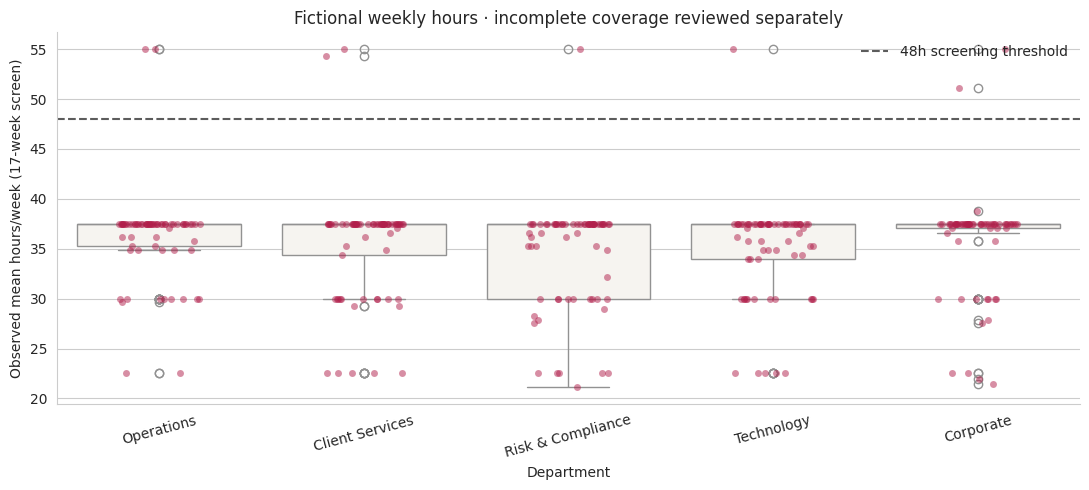

In [8]:
display(result['time_summary'].groupby('result').agg(employees=('employee_id','size'),mean_observed=('average_hours','mean')))
display(result['time_summary'][result['time_summary']['employee_id'].isin(['EMP0100','EMP0103','EMP0150','EMP0170'])])
display(result['exceptions'][result['exceptions']['area'].eq('Working time')])
display(Image(filename=str(OUTPUT / 'plots' / 'working_time.png')))

## 8 / Visa, PIP and ER administration
Fictional metadata illustrates expiry horizons, owner/evidence gaps and overdue review dates. The 90-day review horizon is an operational service-level assumption. Sensitive personal fields and substantive employment decisions are excluded. Provider coordination and specialist HR judgement are represented by proposed procedures; practical experience requires separate evidence.

,case_id,employee_id,expiry_date,days_remaining,status,owner,evidence,result
0,VISA-001,EMP0200,2026-10-16,-15,Submitted,Immigration Coordinator,Pending,Expired / verify
1,VISA-002,EMP0201,2026-10-29,-2,Not started,Immigration Coordinator,Recorded,Expired / verify
2,VISA-003,EMP0202,2026-10-31,0,Not started,Immigration Coordinator,Recorded,0-30 days
3,VISA-004,EMP0203,2026-11-07,7,Not started,Immigration Coordinator,Pending,0-30 days
4,VISA-005,EMP0204,2026-11-15,15,Submitted,Immigration Coordinator,Recorded,0-30 days
5,VISA-006,EMP0205,2026-11-25,25,Not started,Immigration Coordinator,Recorded,0-30 days
6,VISA-007,EMP0206,2026-12-05,35,Not started,Immigration Coordinator,Pending,31-90 days
7,VISA-008,EMP0207,2026-12-15,45,Not started,Immigration Coordinator,Recorded,31-90 days
8,VISA-009,EMP0208,2026-12-30,60,Submitted,,Recorded,31-90 days
9,VISA-010,EMP0209,2027-01-09,70,Not started,Immigration Coordinator,Pending,31-90 days


cases
case_type  result                     
ER triage  Governance follow-up      2
           Scheduled                10
PIP review Governance follow-up      8
           Scheduled                10

severity,High,Review
area,,
Absence,0,5
HR master,0,5
PIP / ER,0,10
Payroll,12,4
Visa,0,12
Working time,0,10


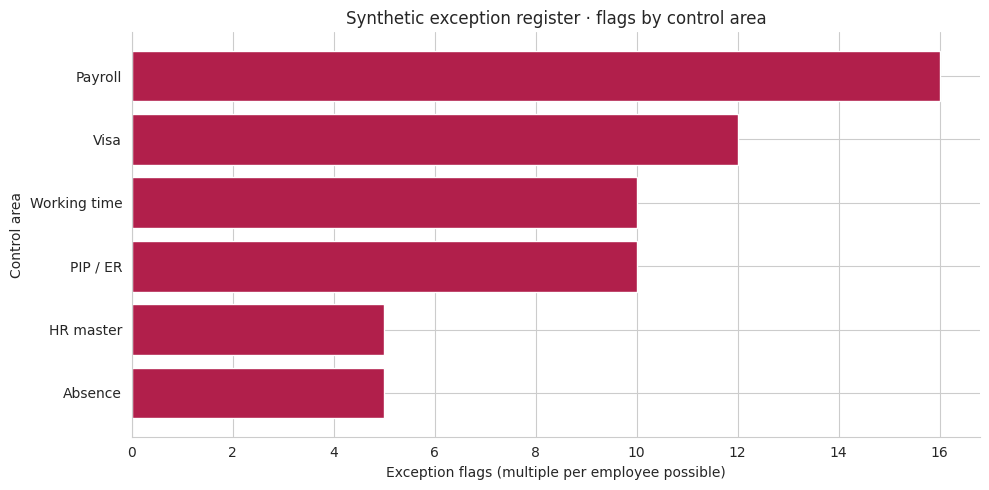

In [9]:
display(result['visa'][['case_id','employee_id','expiry_date','days_remaining','status','owner','evidence','result']])
display(result['cases'].groupby(['case_type','result']).size().to_frame('cases'))
display(result['exceptions'].groupby(['area','severity']).size().unstack(fill_value=0))
display(Image(filename=str(OUTPUT / 'plots' / 'exception_areas.png')))

## 9 / Controls, Excel evidence and requirement coverage
Inspect the native Excel PivotTables and editable formulas. Raw-to-clean transformations and roster membership are regenerated by Python; clean-input formulas and pivots recalculate in Excel. The control designs require operational approval before implementation. Employer impact would need measurement in a live setting.

In [10]:
requirements = pd.DataFrame(json.loads((ROOT/'assets'/'requirements.json').read_text()))
display(requirements)
display(pd.Series(json.loads((OUTPUT/'excel_validation.json').read_text())))
assert json.loads((OUTPUT/'excel_validation.json').read_text())['formula_errors'] == []
assert json.loads((OUTPUT/'excel_validation.json').read_text())['pivot_tables'] == 2
summary = {'public_source': provenance, 'operational_findings': result['qa'], 'requirement_levels': requirements['level'].value_counts().to_dict()}
(OUTPUT/'analysis_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
display(requirements['level'].value_counts().to_frame('requirements'))

,skill,level,evidence,where
0,"Large, imperfect datasets from multiple systems",Demonstrated,"Seven fictional feeds plus 130,536 public cube...",analysis.ipynb Â· Source audit
1,"Extract, combine and structure data",Demonstrated,"Hash-pinned JSON-stat decoding, typed CSV inge...",scripts/sources.py Â· scripts/analysis.py
2,"Cleanse, reconcile and validate",Demonstrated,"Whitespace/case keys, decimal-comma FTE, criti...",Control journey Â· HR Master
3,Discrepancy investigation and root causes,Simulated,Source-linked synthetic scenarios cover an eff...,Investigation desk Â· Approvals
4,Advanced Excel XLOOKUP,Demonstrated,Exact employee and approval lookups with expli...,People_Operations_Control_Workbook.xlsx Â· Rec...
5,INDEX/MATCH and VLOOKUP,Demonstrated,Independent exact-match alternatives alongside...,Workbook Â· Lookup Lab
6,Nested formulas and conditional logic,Demonstrated,"Nested IF/AND checks return ambiguous, missing...",Workbook Â· Reconciliation
7,Excel PivotTables,Demonstrated,Two refreshable native Excel PivotTables summa...,Workbook Â· Payroll Pivot Â· Case Pivot
8,Data validation and conditional formatting,Demonstrated,"Validated exception status list, input thresho...",Workbook Â· Parameters Â· Exceptions
9,"Trends, exceptions and management information",Demonstrated,Public sector time series and synthetic contro...,Public context Â· Control overview


engine                               Microsoft Excel 16.0
formula_count                                       11919
formula_errors                                         []
uncached_formula_cells                                 []
intentional_blank_formula_results                      52
pivot_tables                                            2
dtype: object

,requirements
level,
Demonstrated,14
Simulated,9
Design-only,4
Not evidenced,2


## Findings and next actions

- **344 validated active employees** after applying master-data and employment-date rules; excluded records remain in the audit trail.
- **3 amount discrepancies**: net EUR 1,847.33, absolute EUR 2,652.67, on the same 340-record comparable base.
- **1 overlapping scheduled day(s)** removed from the numerator; worked-time collisions require source review.
- **7 above-screen time records and 1 incomplete record** require HR/legal review of the relevant hours and coverage.
- **10 fictional permissions in the 0–90-day horizon**, plus 2 expired records requiring authorised verification.
- Immediate control priorities: identity uniqueness; approved effective-dated compensation; lifecycle/payroll cutoff; absence overlap/time reconciliation; complete time data; owned visa/case follow-up.
- Before real use: confirm data-owner permissions and AI scope, minimise sensitive fields, add legal/roster/holiday rules, test source-system mappings, obtain HR/payroll/legal review and segregate correction approval.
- CV/interview evidence required: years of experience, live BambooHR capability, immigration administration, Tier 2 ER judgement and hands-on Power BI authoring.